In [2]:
!pip install tensorflow numpy matplotlib scikit-learn pillow
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [21]:
#!pip install tensorflow numpy matplotlib scikit-learn pillow
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D,Flatten, Dense, Dropout
#from tensorflow.keras.layers import Flatten, Dense, Dropout
from sklearn.model_selection import train_test_split

In [4]:
file_path = r"F:\lp4\LP IV Updated Datasets\FNN and CNN\CIFAR10\cifar-10.csv"

data = pd.read_csv(file_path)

print(data.shape)
print(data.head())
print(data.columns[:10])

(50000, 3073)
   pixel_0  pixel_1  pixel_2  pixel_3  pixel_4  pixel_5  pixel_6  pixel_7  \
0       59       43       50       68       98      119      139      145   
1      154      126      105      102      125      155      172      180   
2      255      253      253      253      253      253      253      253   
3       28       37       38       42       44       40       40       24   
4      170      168      177      183      181      177      181      184   

   pixel_8  pixel_9  ...  pixel_3063  pixel_3064  pixel_3065  pixel_3066  \
0      149      149  ...          58          65          59          46   
1      142      111  ...          42          67         101         122   
2      253      253  ...          83          80          69          66   
3       32       43  ...          39          59          42          44   
4      189      189  ...          88          85          82          83   

   pixel_3067  pixel_3068  pixel_3069  pixel_3070  pixel_3071  lab

In [8]:
# Separate pixel values and labels

x = data.drop('label', axis=1).values
y = data['label'].values

print("Features shape:", x.shape)
print("Labels shape:", y.shape)

Features shape: (50000, 3072)
Labels shape: (50000,)


In [9]:
x = x.reshape(-1, 32, 32, 3)

print("Reshaped images:", x.shape)

Reshaped images: (50000, 32, 32, 3)


In [10]:
x = x.astype('float32') / 255.0

In [11]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(
    x, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", x_train.shape)
print("Testing data:", x_test.shape)

Training data: (40000, 32, 32, 3)
Testing data: (10000, 32, 32, 3)


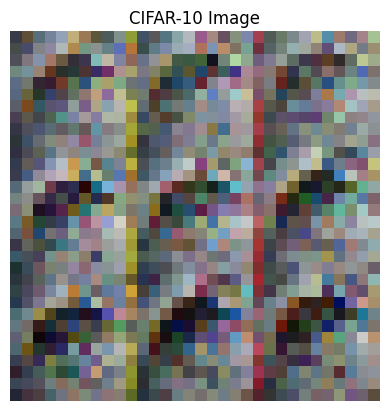

Label: 6


In [12]:
plt.imshow(x_train[0])
plt.title("CIFAR-10 Image")
plt.axis('off')
plt.show()

print("Label:", y_train[0])

In [13]:
model = Sequential([

    # First Convolutional Layer
    Conv2D(32, (3,3), activation='relu',
    input_shape=(32,32,3)),

    # First Pooling Layer
    MaxPooling2D((2,2)),

    # Second Convolutional Layer
    Conv2D(64, (3,3), activation='relu'),

    # Second Pooling Layer
    MaxPooling2D((2,2)),

    # Flatten Layer
    Flatten(),

    # Fully Connected Layer
    Dense(128, activation='relu'),

    # Dropout Layer
    Dropout(0.5),

    # Output Layer
    Dense(10, activation='softmax')
])

C:\Users\Admin\AppData\Roaming\Python\Python313\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [14]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)                    │ (None, 30, 30, 32)          │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 15, 15, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_3 (Conv2D)                    │ (None, 13, 13, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_3 (MaxPooling2D)       │ (None, 6, 6, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_1 (Flatten)                  │ (None, 2304)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 128)                 │         295,040 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 315,722 (1.20 MB)

 Trainable params: 315,722 (1.20 MB)

 Non-trainable params: 0 (0.00 B)

In [15]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [18]:
history = model.fit(
    x_train, y_train,
    epochs=10,
    batch_size=32,
    validation_split=0.1
)

Epoch 1/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 49s 43ms/step - accuracy: 0.5642 - loss: 1.2327 - val_accuracy: 0.5735 - val_loss: 1.2317
Epoch 2/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 46s 41ms/step - accuracy: 0.5771 - loss: 1.1950 - val_accuracy: 0.5970 - val_loss: 1.1615
Epoch 3/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 41s 36ms/step - accuracy: 0.5905 - loss: 1.1483 - val_accuracy: 0.6047 - val_loss: 1.1515
Epoch 4/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 33s 29ms/step - accuracy: 0.6024 - loss: 1.1149 - val_accuracy: 0.6000 - val_loss: 1.1606
Epoch 5/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 35s 31ms/step - accuracy: 0.6102 - loss: 1.0931 - val_accuracy: 0.6097 - val_loss: 1.1307
Epoch 6/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 35s 31ms/step - accuracy: 0.6211 - loss: 1.0610 - val_accuracy: 0.6118 - val_loss: 1.1329
Epoch 7/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 33s 29ms/step - accuracy: 0.6284 - loss: 1.0301 - val_accuracy: 0.6133 - val_loss: 1.1269
Epoch 8/10
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 33s 30ms/step - accuracy: 0.6425 -

313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.6136 - loss: 1.1270
Test Loss: 1.127045750617981
Test Accuracy: 0.6136000156402588


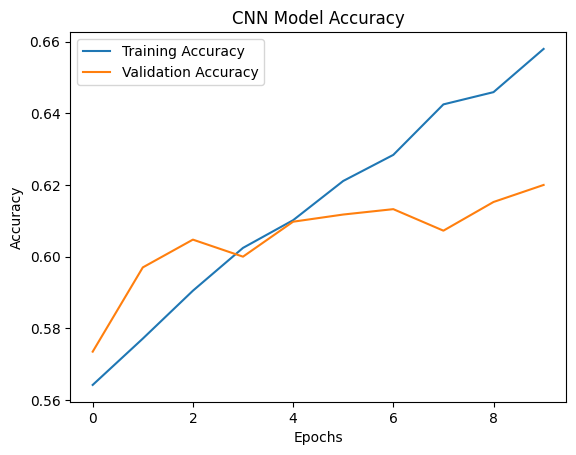

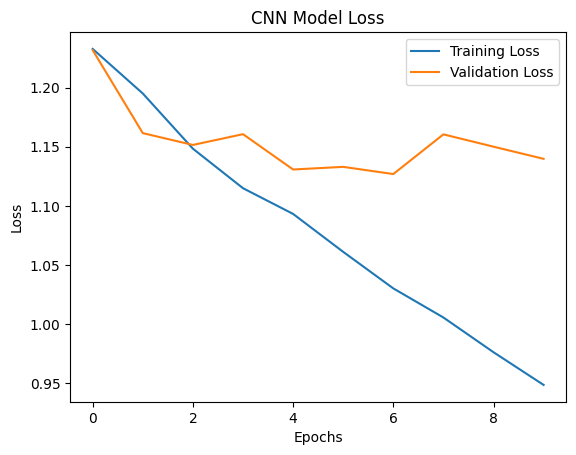

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 107ms/step


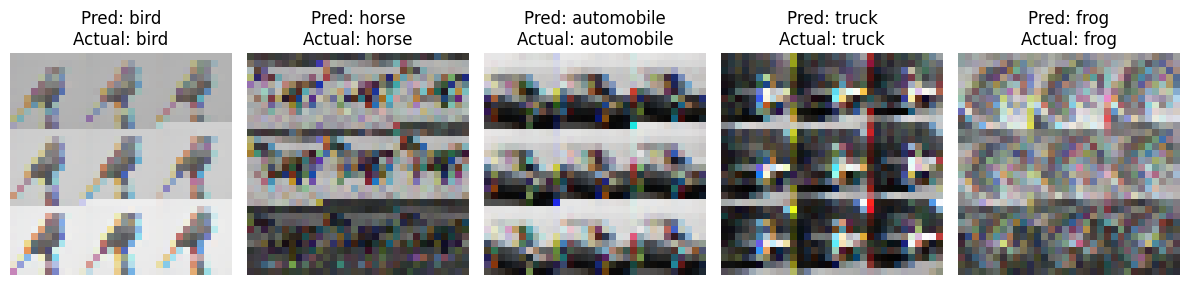

In [19]:
test_loss, test_accuracy = model.evaluate(
    x_test, y_test
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])

plt.title('CNN Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')

plt.legend(['Training Accuracy', 'Validation Accuracy'])
plt.show()

plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])

plt.title('CNN Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')

plt.legend(['Training Loss', 'Validation Loss'])
plt.show()


class_names = [
    'airplane', 'automobile', 'bird', 'cat', 'deer',
    'dog', 'frog', 'horse', 'ship', 'truck'
]

predictions = model.predict(x_test[:5])

plt.figure(figsize=(12,5))

for i in range(5):
    plt.subplot(1,5,i+1)

    plt.imshow(x_test[i])

    predicted_label = np.argmax(predictions[i])
    actual_label = y_test[i]

    plt.title(
        f"Pred: {class_names[predicted_label]}\n"
        f"Actual: {class_names[actual_label]}"
    )

    plt.axis('off')

plt.tight_layout()
plt.show()


1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step


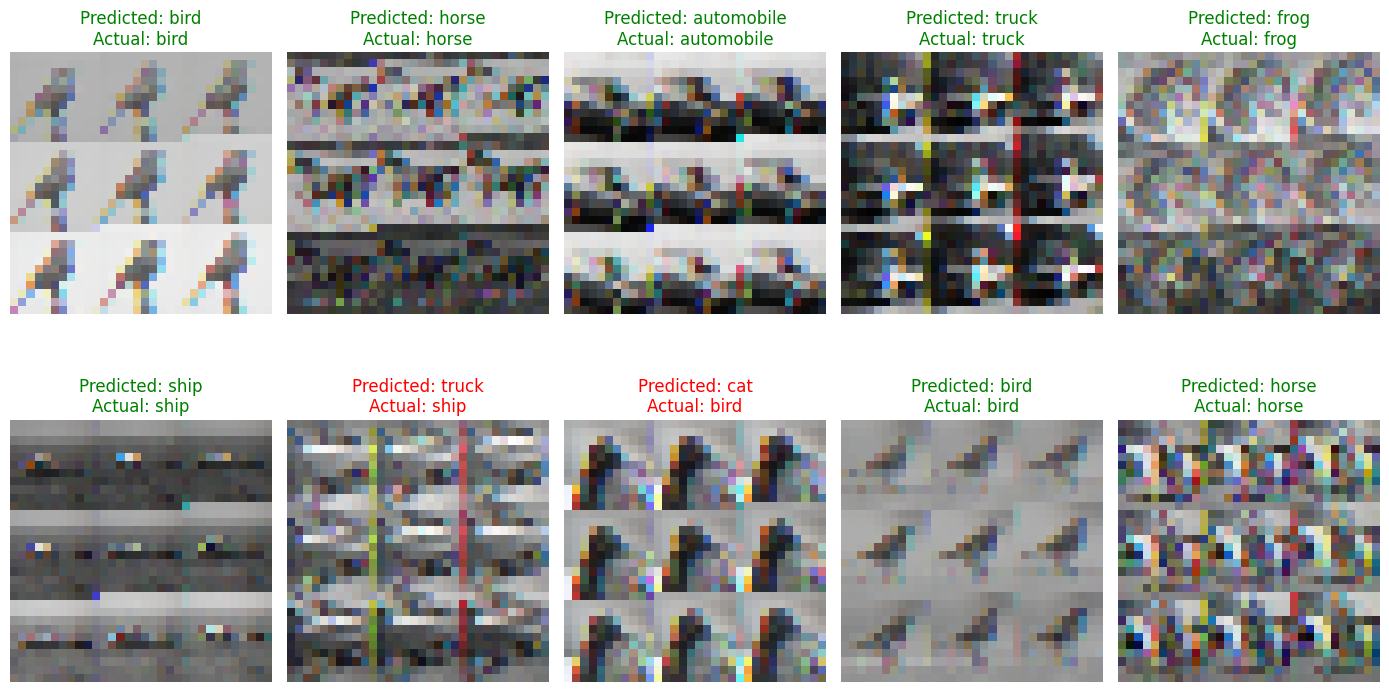

In [20]:
class_names = [
    'airplane', 'automobile', 'bird', 'cat', 'deer',
    'dog', 'frog', 'horse', 'ship', 'truck'
]

predictions = model.predict(x_test[:10])

plt.figure(figsize=(14, 8))

for i in range(10):
    plt.subplot(2, 5, i+1)

    plt.imshow(x_test[i])

    predicted = np.argmax(predictions[i])
    actual = y_test[i]

    color = 'green' if predicted == actual else 'red'

    plt.title(
        f"Predicted: {class_names[predicted]}\n"
        f"Actual: {class_names[actual]}",
        color=color
    )

    plt.axis('off')

plt.tight_layout()
plt.show()